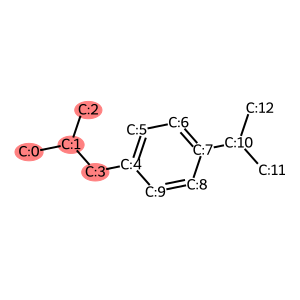

In [89]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem

def draw_highlighted_atoms(mol, atom_ids):
    
    for i, atom in enumerate(mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

# Example usage
smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(smiles)

# List of atom indices to highlight
atom_ids = [0, 1, 2, 3]

# Draw the molecule with highlighted atoms
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

In [90]:
def extract_substructure(mol, atom_ids):
    # Create an empty molecule and add only the atoms of interest
    new_mol = Chem.RWMol()

    # Add atoms that are in the atom_ids list to the new molecule
    atom_map = {}
    for atom_idx in atom_ids:
        atom = mol.GetAtomWithIdx(atom_idx)
        new_atom_idx = new_mol.AddAtom(atom)
        atom_map[atom_idx] = new_atom_idx

    # Now we add the bonds that correspond to the atoms in atom_ids

    for bond in mol.GetBonds():
        idx1 = bond.GetBeginAtomIdx()
        idx2 = bond.GetEndAtomIdx()

        # Check if both atoms are in the atom_ids list, if so, add the bond
        if idx1 in atom_ids and idx2 in atom_ids:
            new_mol.AddBond(atom_map[idx1], atom_map[idx2], bond.GetBondType())

        elif idx1 in atom_ids or idx2 in atom_ids:
            dummy_atm = AllChem.Atom(0)
            if idx1 in atom_ids:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx1], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                new_mol.GetAtomWithIdx(atom_map[idx1]).GetImplicitValence()
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNumExplicitHs(0)
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNoImplicit(False)
                new_mol.GetAtomWithIdx(atom_map[idx1]).SetNoImplicit(False)
            else:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx2], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                new_mol.GetAtomWithIdx(atom_map[idx2]).GetImplicitValence()
                new_mol.GetAtomWithIdx(atom_map[idx2]).SetNumExplicitHs(0)
                new_mol.GetAtomWithIdx(atom_map[idx2]).SetNoImplicit(False)


    # Get the substructure as a SMILES string
    #rdmolops.SetAromaticity(new_mol)
    #Chem.SanitizeMol(new_mol, Chem.rdmolops.SanitizeFlags.SANITIZE_ALL)
    new_mol.UpdatePropertyCache()
    mw = Descriptors.ExactMolWt(new_mol)
    substructure_smiles = Chem.MolToSmiles(new_mol, )
    #substructure_smiles = Chem.MolToSMILES(new_mol, isomericSmiles=True)
    print(f"Substructure SMILES: {substructure_smiles}")
    print(f"Substructure base mass: {mw}")
    return substructure_smiles

def match_smile_substructure(target_smiles, substructure_smiles):
    print("Target SMILES:", target_smiles)
    print("Substructure SMILES:", substructure_smiles)
    target_mol = Chem.MolFromSmiles(target_smiles)
    #Chem.SanitizeMol(target_mol)
    # do not sanitize the substructure
    #substructure_mol = Chem.MolFromSmiles(substructure_smiles, sanitize=False)
    substructure_mol = Chem.MolFromSmarts(substructure_smiles)

    # Perform substructure match
    matches = target_mol.GetSubstructMatches(substructure_mol)
    return matches

Substructure SMILES: *CC(C)C
Substructure base mass: 57.070425287999996


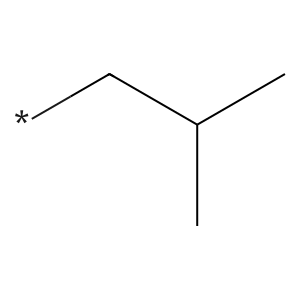

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMILES: *CC(C)C
Substructure Matches: ((4, 3, 1, 0, 2),)


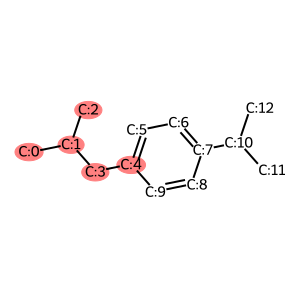

In [91]:
# Example usage
target_smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(target_smiles)
# Kekulize the molecule (convert aromatic bonds to single and double bonds)
#Chem.Kekulize(mol, clearAromaticFlags=True)
# Optionally, sanitize the molecule
# Chem.SanitizeMol(mol)

# List of atom indices to form the substructure
atom_ids = [0, 1, 2, 3]

# Extract substructure from atom indices
substructure_smiles = extract_substructure(mol, atom_ids)
#substructure_smart = substructure_smart.replace('[#0]', '[!H]')
#print("Substructure SMILES:", substructure_smiles)
sub_mol = Chem.MolFromSmiles(substructure_smiles)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show() # This will display the image of the substructure

# Perform substructure match with the target molecule
matches = match_smile_substructure(target_smiles, substructure_smiles)
print("Substructure Matches:", matches)

highlighted_image = draw_highlighted_atoms(mol, matches[0])
highlighted_image.show()  # This will display the image

Substructure SMILES: *[c:7](*)[CH:10]([CH3:11])[CH3:12]
Substructure base mass: 55.054775224
Substructure SMILES: *[c:7](*)[CH:10]([CH3:11])[CH3:12]


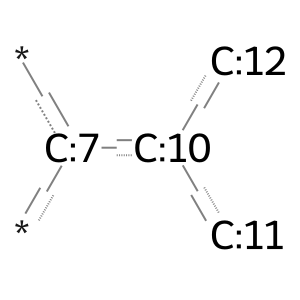

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMILES: *[c:7](*)[CH:10]([CH3:11])[CH3:12]
Substructure Matches: ((6, 7, 8, 10, 11, 12),)


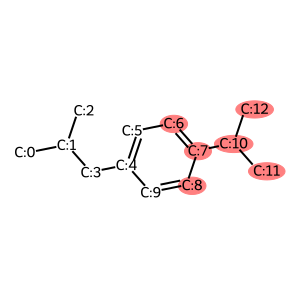

In [92]:
# Extract substructure from atom indices
atom_ids = [7, 10, 11, 12]
substructure_smart = extract_substructure(mol, atom_ids)
print("Substructure SMILES:", substructure_smart)
substructure_smart = substructure_smart.replace('[#0]', '[!H]')
sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

# Perform substructure match with the target molecule
matches = match_smile_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)

highlighted_image = draw_highlighted_atoms(mol, matches[0])
highlighted_image.show()  # This will display the image
